Our first problem is a modern version of the canonical binary classification problem:
spam classification.

We will use the SMS Spam Classification Data Set from the UCI Machine Learning Repository. The dataset can be downloaded from http://archive.ics.uci.edu/ml/datasets/SMS+Spam+Collection. First, let's explore the data set and calculate some basic summary statistics using pandas:

In [12]:
import pandas as pd

In [13]:
df = pd.read_csv('data/SMSSpamCollection', delimiter='\t',header=None)
print(df.head())


      0                                                  1
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [14]:
print('Number of spam messages:', df[df[0] == 'spam'][0].count())

Number of spam messages: 747


In [15]:
print('Number of ham messages:', df[df[0] == 'ham'][0].count())

Number of ham messages: 4825


Let's make some predictions using scikit-learn's LogisticRegression class:

In [16]:
import numpy as np 
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score

In [17]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(df[1],df[0])

接下来，我们创建一个TfidfVectorizer，用户转换读取的文本。

In [18]:
vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

我们创建一个 LogisticRegression 实例并训练我们的模型。

In [19]:
classifier = LogisticRegression()

# 训练
classifier.fit(X_train, y_train)

# 预测
predictions = classifier.predict(X_test)
# 查看预测结果
for i, prediction in enumerate(predictions[:5]):
 print('Prediction result: %s. \t Message: %s\n' % (prediction, X_test_raw.iloc[i]))

Prediction result: ham. 	 Message: Do you mind if I ask what happened? You dont have to say if it is uncomfortable.

Prediction result: ham. 	 Message: Kothi print out marandratha.

Prediction result: ham. 	 Message: Sounds like there could be a lot of time spent in that chastity device boy ... *grins* ... Or take your beatings like a good dog. Going to lounge in a nice long bath now ?

Prediction result: ham. 	 Message: No sir. That's why i had an 8-hr trip on the bus last week. Have another audition next wednesday but i think i might drive this time.

Prediction result: ham. 	 Message: Ü neva tell me how i noe... I'm not at home in da aft wat... 



## classification Perfromence metrics

In [20]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [21]:
 y_test = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
 y_pred = [0, 1, 0, 0, 0, 0, 0, 1, 1, 1]
 confusion_matrix = confusion_matrix(y_test, y_pred)
 print(confusion_matrix)


[[4 1]
 [2 3]]


 plt.matshow(confusion_matrix)
 plt.title('Confusion matrix')
 plt.colorbar()
 plt.ylabel('True label')
 plt.xlabel('Predicted label')
 plt.show()

## Accuracy 准确率

In [23]:
from sklearn.metrics import accuracy_score


In [24]:
y_pred, y_true = [0, 1, 1, 0], [1, 1, 1, 1]
print('Accuracy:', accuracy_score(y_true, y_pred))

Accuracy: 0.5


LogisticRegression.score() predicts and scores labels for a test set using accuracy.

In [32]:
scores = cross_val_score(classifier, X_train, y_train, cv=5)
print(np.mean(scores), scores)

0.955971406469358 [0.95454545 0.95334928 0.95813397 0.95334928 0.96047904]


准确率衡量的是分类器的整体正确性，但它无法区分假阳性错误和假阴性错误。某些应用程序可能对假阴性比假阳性更敏感，反之亦然。此外，如果类别的比例在总体中出现偏差，准确率就不是一个有用的指标。

## Precision 精确率 & Recall 召回率

精确率是指正确的阳性预测在全部阳性预测的比例。

召回率是指分类器识别出的真正阳性样本在真实阳性样本的占比。

scikit-learn provides a function to calculate the precision and recall for a classifier from a set of predictions and the corresponding set of trusted labels.

当使用 scoring='precision'、scoring='recall'、scoring='f1' 等指标时：

这些指标需要明确知道哪个是"正类"（positive class），因此需要先处理一下y_train

In [40]:
from sklearn.preprocessing import LabelEncoder

# 将字符串标签转换为数值
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)

# 现在使用编码后的标签
precisions = cross_val_score(classifier, X_train, y_train_encoded, cv=5, scoring='precision')
print('mean Precision :{0}, each precision: {1}'.format( np.mean(precisions), precisions))

mean Precision :0.989470036838458, each precisions: [0.98648649 0.97368421 0.98717949 1.         1.        ]


In [41]:
recalls = cross_val_score(classifier, X_train, y_train_encoded, cv=5, scoring='recall')
print('mean Recall: {0}, each Recall : {1}'.format( np.mean(recalls), recalls))

mean Recall: 0.6745290745290745, each Recall : [0.66363636 0.66666667 0.69369369 0.64864865 0.7       ]


## F1分数

In [43]:
f1s = cross_val_score(classifier, X_train, y_train_encoded, cv=5, scoring='f1')
print ('mean F1 : {0}, each F1:{1}'.format( np.mean(f1s), f1s))

mean F1 : 0.8020303167236209, each F1:[0.79347826 0.79144385 0.81481481 0.78688525 0.82352941]


## AUC

In [45]:
from sklearn.metrics import roc_curve, auc

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score

df = pd.read_csv('data/SMSSpamCollection', delimiter='\t',header=None)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(df[1],df[0])


vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

# 我们创建一个 LogisticRegression 实例并训练我们的模型。

classifier = LogisticRegression()

# 训练
classifier.fit(X_train, y_train)

# 预测
# predictions = classifier.predict(X_test)


predictions = classifier.predict_proba(X_test)
false_positive_rate, recall, thresholds = roc_curve(y_test, predictions[:, 1],pos_label='spam')
roc_auc = auc(false_positive_rate, recall)


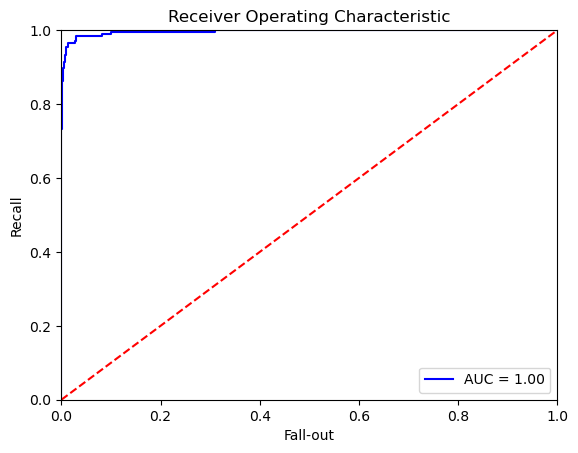

In [58]:
plt.title('Receiver Operating Characteristic')
plt.plot(false_positive_rate, recall, 'b', label='AUC = %0.2f' % roc_auc)
plt.legend(loc='lower right')
plt.plot([0, 1], [0, 1], 'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.ylabel('Recall')
plt.xlabel('Fall-out')
plt.show()


对角线：随机猜测模型的性能
左下角 (0,0)：阈值最高，所有样本预测为负例
右上角 (1,1)：阈值最低，所有样本预测为正例

从 ROC AUC 图可以看出，我们的分类器明显优于随机猜测；大部分绘图区域位于其曲线下方：